# Waste Classification – Dataset Exploration

Explore the dataset, understand its structure, count images per category, and check for class imbalance.

### Waste Categories
1. Cardboard
2. Food Organics
3. Glass
4. Metal
5. Miscellaneous Trash
6. Paper
7. Plastic
8. Textile Trash
9. Vegetation

### Import Needed Libraries 


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import sklearn


### It checks each category folder and counts its JPG and PNG images.


In [17]:
from pathlib import Path

dataset_path = Path("../data/Waste_Dataset")

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        images = [
            file for file in folder.iterdir()
            if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]
        print(f"{folder.name}: {len(images)} images")
        

1-Cardboard: 461 images
2-Food Organics: 411 images
3-Glass: 420 images
4-Metal: 790 images
5-Miscellaneous Trash: 495 images
6-Paper: 500 images
7-Plastic: 921 images
8-Textile Trash: 318 images
9-Vegetation: 436 images


### A bar chart makes it easier to identify class imbalance visually.

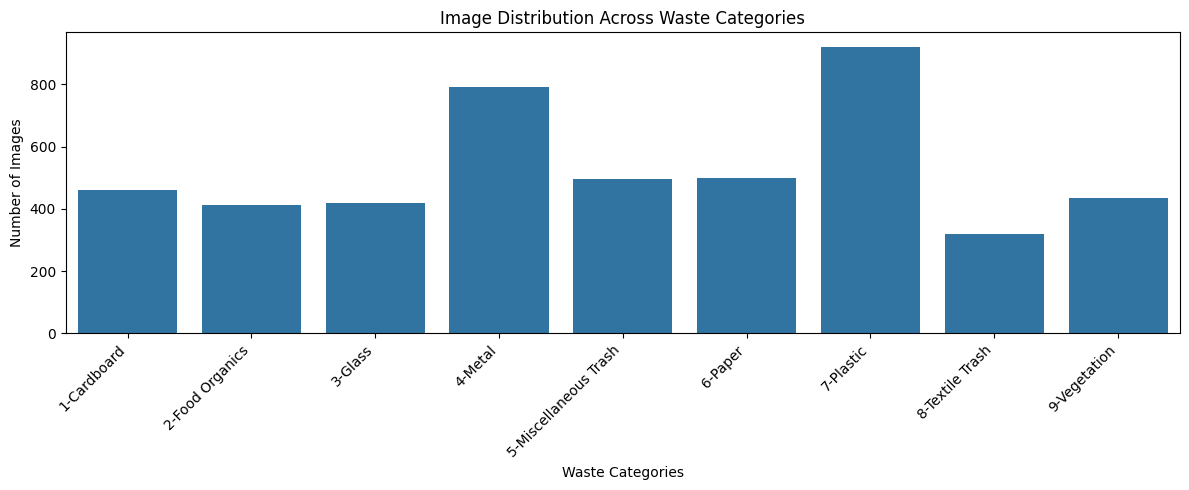

In [18]:
categories = []
counts = []

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        images = [
            f for f in folder.iterdir()
            if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]
        categories.append(folder.name)
        counts.append(len(images))

plt.figure(figsize=(12, 5))
sns.barplot(x=categories, y=counts)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Waste Categories")
plt.ylabel("Number of Images")
plt.title("Image Distribution Across Waste Categories")
plt.tight_layout()
plt.show()

### Selects one random image from each category. Reads it using OpenCV.
### Converts BGR to RGB so Matplotlib displays the correct colours.
### Displays the image with its category name.

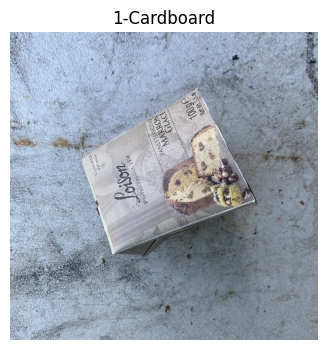

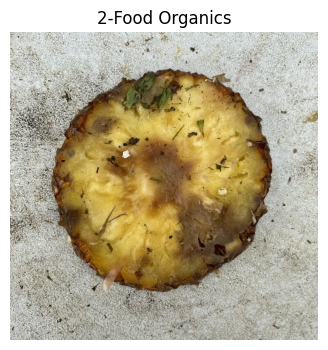

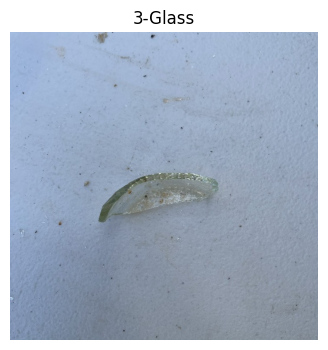

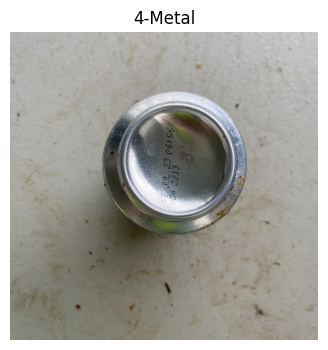

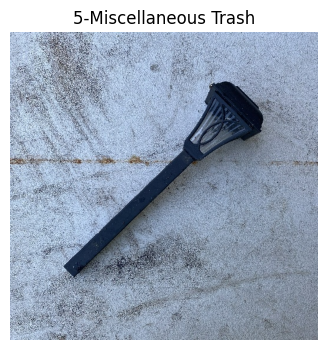

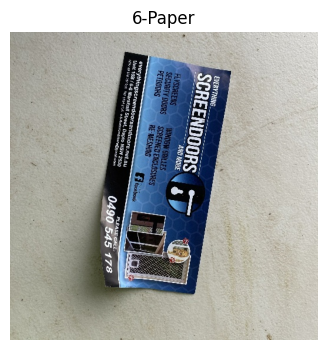

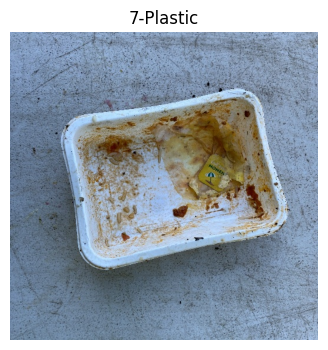

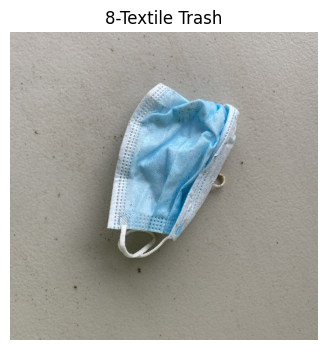

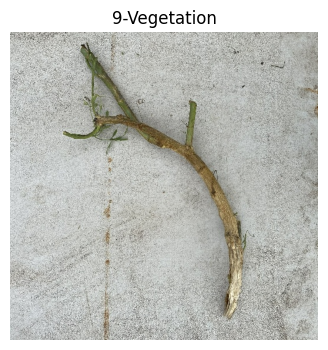

In [19]:
import random

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        images = list(folder.glob("*.jpg")) + list(folder.glob("*.png"))
        image_path = random.choice(images)

        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(4, 4))
        plt.imshow(image)
        plt.title(folder.name)
        plt.axis("off")
        plt.show()

#### Whether images have different dimensions.Whether any images are corrupted. 
#### Whether resizing will be necessary.

In [ ]:
dimensions = []
corrupted = 0

for folder in dataset_path.iterdir():
    if folder.is_dir():
        for file in folder.iterdir():
            if file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                image = cv2.imread(str(file))

                if image is None:
                    corrupted += 1
                else:
                    height, width = image.shape[:2]
                    dimensions.append((width, height))

print("Total readable images:", len(dimensions))
print("Corrupted images:", corrupted)
print("Unique image dimensions:", len(set(dimensions)))
print("Smallest dimensions:", min(dimensions, key=lambda x: x[0] * x[1]))
print("Largest dimensions:", max(dimensions, key=lambda x: x[0] * x[1]))


Total readable images: 4752
Corrupted images: 0
Unique image dimensions: 1
Smallest dimensions: (524, 524)
Largest dimensions: (524, 524)
